# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

1. 1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**


In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt


In [2]:
meta = pd.read_csv('./data/metabric.csv')
meta.head(5)

,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Chemotherapy,Hormone Therapy,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),Overall Survival Status,Radio Therapy,TMB (nonsynonymous),Tumor Size,Tumor Stage
0,43.19,BREAST CONSERVING,Breast Cancer,NO,YES,0.0,2.0,4.020,84.633333,0:LIVING,YES,2.615035,10.0,1.0
1,48.87,MASTECTOMY,Breast Cancer,YES,YES,1.0,2.0,4.030,163.700000,1:DECEASED,NO,2.615035,15.0,2.0
2,47.68,MASTECTOMY,Breast Cancer,YES,YES,3.0,1.0,4.050,164.933333,0:LIVING,YES,1.307518,25.0,2.0
3,76.97,MASTECTOMY,Breast Cancer,YES,YES,8.0,2.0,6.080,41.366667,1:DECEASED,YES,2.615035,40.0,2.0
4,78.77,MASTECTOMY,Breast Cancer,NO,YES,0.0,4.0,4.062,7.800000,1:DECEASED,YES,5.230071,31.0,4.0


In [3]:
meta['Overall Survival Status'].value_counts()

Overall Survival Status
1:DECEASED    768
0:LIVING      575
Name: count, dtype: int64

<Axes: xlabel='Overall Survival (Months)', ylabel='Density'>

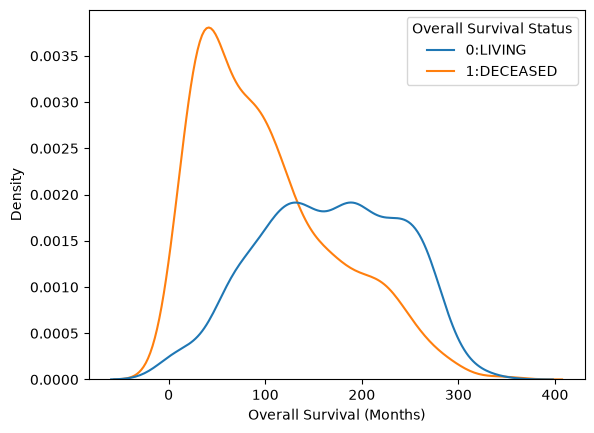

In [4]:
sns.kdeplot( data = meta,
            x = 'Overall Survival (Months)',
            hue = 'Overall Survival Status'
)

In [5]:
meta = meta[meta["Tumor Stage"] != 0 ]

2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.

In [6]:
meta['log_months'] = np.log(meta['Overall Survival (Months)'])

In [7]:
from sklearn.model_selection import train_test_split

train , test = train_test_split(
    meta,
    test_size = .2,
    random_state=42
)

In [8]:
meta.columns.tolist()

['Age at Diagnosis',
 'Type of Breast Surgery',
 'Cancer Type',
 'Chemotherapy',
 'Hormone Therapy',
 'Lymph nodes examined positive',
 'Mutation Count',
 'Nottingham prognostic index',
 'Overall Survival (Months)',
 'Overall Survival Status',
 'Radio Therapy',
 'TMB (nonsynonymous)',
 'Tumor Size',
 'Tumor Stage',
 'log_months']

In [9]:
numeric = [
    'Age at Diagnosis',
    'Lymph nodes examined positive',
    'Mutation Count',
    'Tumor Size'
]

categorical = [
    'Chemotherapy',
    'Hormone Therapy',
    'Radio Therapy',
    'Tumor Stage'
]

## Model 1: Impute the available Data 

In [10]:
X_train = train[numeric + categorical]
y_train = train['log_months']
X_train = pd.get_dummies(X_train, columns=categorical, drop_first=True, dtype=int)

X_test = pd.get_dummies(
    test[numeric + categorical],
    columns=categorical,
    drop_first=True,
    dtype=int
)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)


In [11]:
X_train.isna().sum()

Age at Diagnosis                 0
Lymph nodes examined positive    0
Mutation Count                   0
Tumor Size                       0
Chemotherapy_YES                 0
Hormone Therapy_YES              0
Radio Therapy_YES                0
Tumor Stage_2.0                  0
Tumor Stage_3.0                  0
Tumor Stage_4.0                  0
dtype: int64

In [12]:
y_train.isna().sum()

np.int64(0)

In [13]:
from sklearn.linear_model import LinearRegression

model1 = LinearRegression()

model1.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[-0.01,-0.04, 0.01,...,-0.19,-0.41,-0.71]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['Age at Diagnosis','Lymph nodes examined positive','Mutation Count',..., 'Tumor Stage_2.0','Tumor Stage_3.0','Tumor Stage_4.0']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.293
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)


In [14]:
model1_predictions =  model1.predict(X_test)
model1_coefficients = pd.Series(
    model1.coef_,
    index=X_train.columns
)

model1_intercept = model1.intercept_

In [15]:
print("\nIntercept:")
print(model1_intercept)

print("\nCoefficients:")
print(model1_coefficients)

print("\nFirst 5 test-set predictions (log-months):")
print(model1_predictions[:5])


Intercept:
5.293352078190799

Coefficients:
Age at Diagnosis                -0.008551
Lymph nodes examined positive   -0.038357
Mutation Count                   0.006382
Tumor Size                      -0.003829
Chemotherapy_YES                -0.219118
Hormone Therapy_YES              0.086354
Radio Therapy_YES                0.120239
Tumor Stage_2.0                 -0.187168
Tumor Stage_3.0                 -0.405198
Tumor Stage_4.0                 -0.707348
dtype: float64

First 5 test-set predictions (log-months):
[4.77950166 4.98594674 4.63098069 4.77563875 4.38807325]


In [16]:
print("\nFirst 5 predictions in months:")
print(np.exp(model1_predictions[:5]))


First 5 predictions in months:
[119.04501049 146.34205795 102.61464806 118.58603702  80.48519428]


## Model2 : Drop the Survived = 1 Rows

In [17]:
train['Overall Survival Status'].value_counts()

Overall Survival Status
1:DECEASED    615
0:LIVING      457
Name: count, dtype: int64

In [18]:
train_deceased = train[
    train['Overall Survival Status'] == '1:DECEASED'
].copy()

In [19]:
X_train2 = train_deceased[numeric + categorical]
y_train2 = train_deceased['log_months']

In [20]:
X_train2 = train_deceased[numeric + categorical]
y_train2 = train_deceased['log_months']

X_train2 = pd.get_dummies(
    X_train2,
    columns=categorical,
    drop_first=True,
    dtype=int
)

X_train2 = X_train2.reindex(
    columns=X_train.columns,
    fill_value=0
)

print(X_train2.shape)

(615, 10)


In [21]:
model2 = LinearRegression()
model2.fit(X_train2, y_train2)

model2_predictions = model2.predict(X_test)

model2_coefficients = pd.Series(
    model2.coef_,
    index=X_train2.columns
)

model2_intercept = model2.intercept_

print("Intercept:", model2_intercept)
print("\nCoefficients:")
print(model2_coefficients)

print("\nFirst 5 predictions in months:")
print(np.exp(model2_predictions[:5]))

Intercept: 4.659418867193347

Coefficients:
Age at Diagnosis                -0.002901
Lymph nodes examined positive   -0.027944
Mutation Count                   0.009611
Tumor Size                      -0.001833
Chemotherapy_YES                -0.393093
Hormone Therapy_YES              0.242348
Radio Therapy_YES                0.039192
Tumor Stage_2.0                 -0.223816
Tumor Stage_3.0                 -0.552826
Tumor Stage_4.0                 -1.049910
dtype: float64

First 5 predictions in months:
[ 89.8218259  100.73971398  88.27005835  90.41930849  54.32849466]


In [22]:
model2_coefficients = pd.Series(
    model2.coef_,
    index=X_train2.columns
)

model2_intercept = model2.intercept_

print("\nIntercept:")
print(model2_intercept)

print("\nCoefficients:")
print(model2_coefficients)

print("\nFirst 5 predictions (months):")
print(np.exp(model2_predictions[:5]))


Intercept:
4.659418867193347

Coefficients:
Age at Diagnosis                -0.002901
Lymph nodes examined positive   -0.027944
Mutation Count                   0.009611
Tumor Size                      -0.001833
Chemotherapy_YES                -0.393093
Hormone Therapy_YES              0.242348
Radio Therapy_YES                0.039192
Tumor Stage_2.0                 -0.223816
Tumor Stage_3.0                 -0.552826
Tumor Stage_4.0                 -1.049910
dtype: float64

First 5 predictions (months):
[ 89.8218259  100.73971398  88.27005835  90.41930849  54.32849466]


In [23]:
comparison = pd.DataFrame({
    'Model 1 (Imputation)': model1_coefficients,
    'Model 2 (Missing Data)': model2_coefficients
})

print(comparison)

                               Model 1 (Imputation)  Model 2 (Missing Data)
Age at Diagnosis                          -0.008551               -0.002901
Lymph nodes examined positive             -0.038357               -0.027944
Mutation Count                             0.006382                0.009611
Tumor Size                                -0.003829               -0.001833
Chemotherapy_YES                          -0.219118               -0.393093
Hormone Therapy_YES                        0.086354                0.242348
Radio Therapy_YES                          0.120239                0.039192
Tumor Stage_2.0                           -0.187168               -0.223816
Tumor Stage_3.0                           -0.405198               -0.552826
Tumor Stage_4.0                           -0.707348               -1.049910


In [24]:
print("Model 1:", X_train.shape)
print("Model 2:", X_train2.shape)


Model 1: (1072, 10)
Model 2: (615, 10)


### WRITTEN ANSWERS:

- **MODEL 1 :** Model 1 treats the observed Survival time(for the duration of the study) as the actual survival time for the lliving patients; this proc ess severely underestimates the survival time of patients who are alive after the conducted study.
- **MODEL 2 :** This approach excludes patients who were still alive at the end of the study and fits the regression using only dead patients. It treats the unobserved eventual survival times of living patients as missing data and discards their available follow up info. This causes selective bias.



3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).

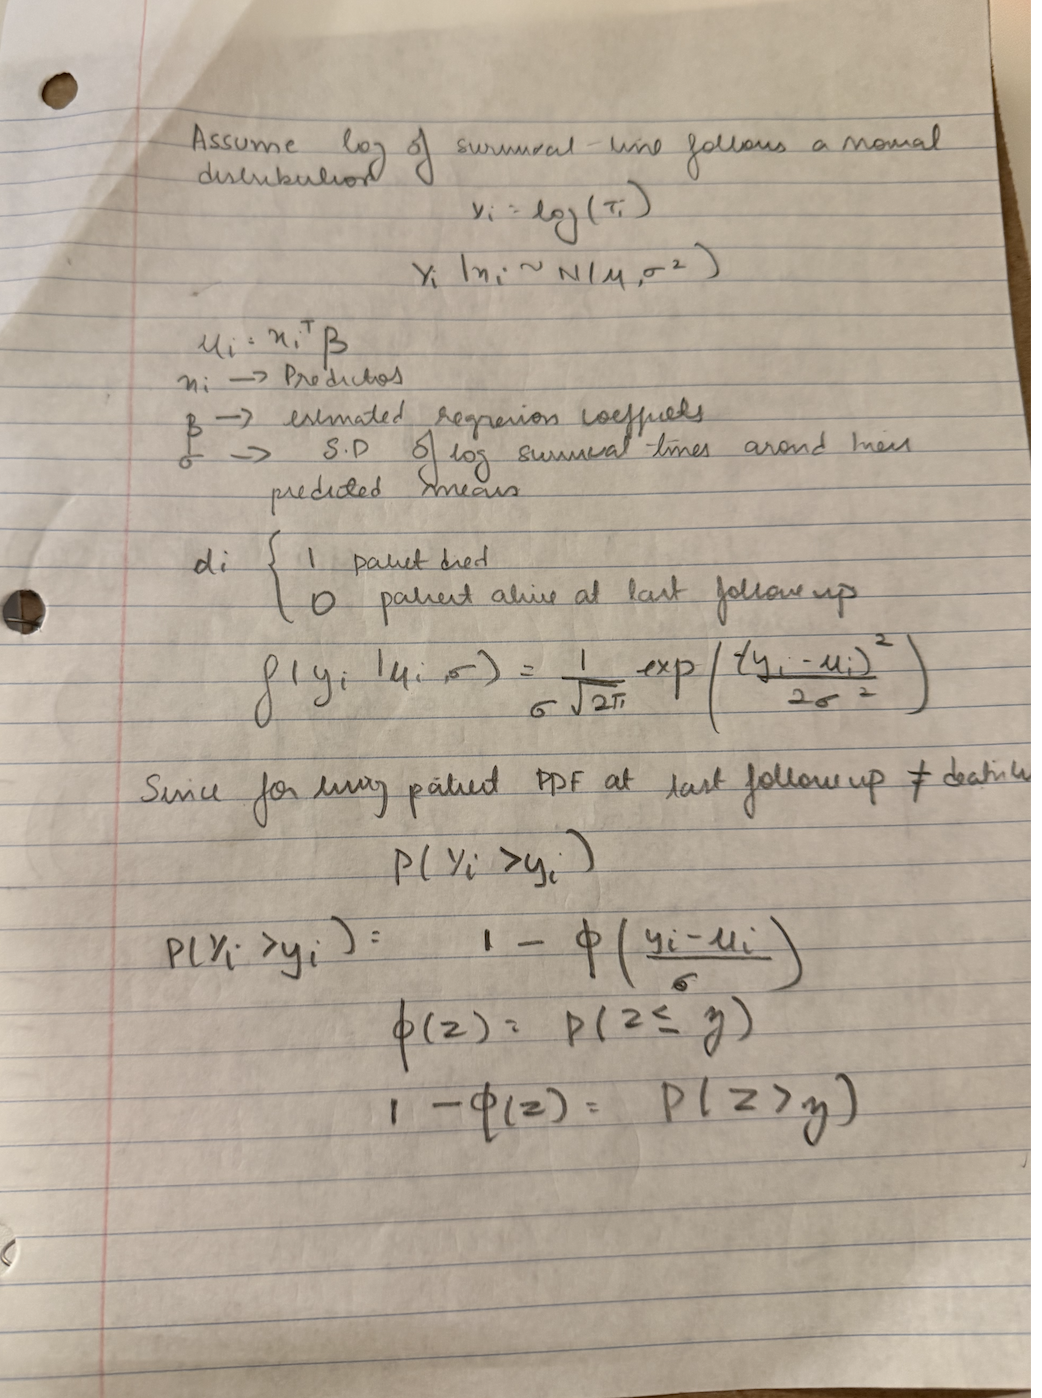

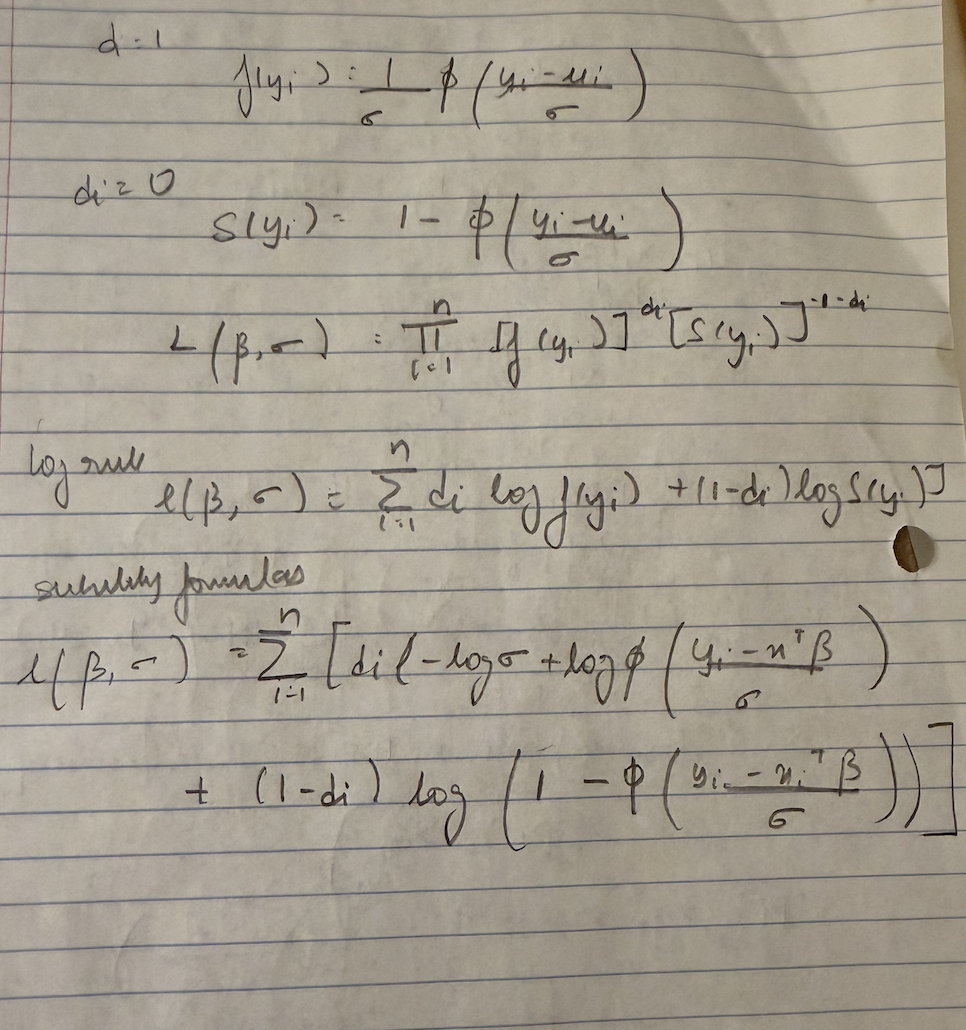

In [25]:
from scipy.stats import norm 

def censored_loglik(beta, sigma, X, y, event):
    mu = X @ beta

    z= (y- mu)/sigma

    loglik = np.where(
        event == 1,
        norm.logpdf(y, loc=mu, scale=sigma),
        norm.logsf(z)
    )

    return np.sum(loglik)

In [26]:
train['event'] = (
    train['Overall Survival Status'] == '1:DECEASED'
).astype(int)

print(train['event'].value_counts())

event
1    615
0    457
Name: count, dtype: int64


In [27]:
print(X_train.shape)
print(y_train.shape)
print(model1.intercept_)
print(len(model1.coef_))

(1072, 10)
(1072,)
5.293352078190799
10


In [28]:
import statsmodels.api as sm

# Add the intercept to the predictor matrix
X_train = sm.add_constant(X_train, has_constant="add")

# Fit the OLS model your professor's code expects
ols_all = sm.OLS(y_train, X_train).fit()

In [29]:
from statsmodels.base.model import GenericLikelihoodModel

class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

start = np.r_[ols_all.params, np.log(np.sqrt(np.mean(ols_all.resid ** 2)))]

model = CensoredNormalMLE(y_train, X_train, train["event"])
mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
print(mle.summary())

Converged: True
                          CensoredNormalMLE Results                           
Dep. Variable:             log_months   Log-Likelihood:                -1201.4
Model:              CensoredNormalMLE   AIC:                             2427.
Method:            Maximum Likelihood   BIC:                             2487.
Date:                Wed, 18 Nov 2026                                         
Time:                        18:44:54                                         
No. Observations:                1072                                         
Df Residuals:                    1060                                         
Df Model:                          10                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                             6.7612      0.232     29.142      0.000    

In [30]:
comparison = pd.DataFrame({
    "Model 1": np.r_[model1.intercept_, model1.coef_],
    "Model 2": np.r_[model2.intercept_, model2.coef_],
    "Censored MLE": mle.params[:-1]
}, index=X_train.columns)

print(comparison.round(4))

                               Model 1  Model 2  Censored MLE
const                           5.2934   4.6594        6.7612
Age at Diagnosis               -0.0086  -0.0029       -0.0218
Lymph nodes examined positive  -0.0384  -0.0279       -0.0567
Mutation Count                  0.0064   0.0096       -0.0168
Tumor Size                     -0.0038  -0.0018       -0.0087
Chemotherapy_YES               -0.2191  -0.3931       -0.2726
Hormone Therapy_YES             0.0864   0.2423        0.2613
Radio Therapy_YES               0.1202   0.0392        0.2135
Tumor Stage_2.0                -0.1872  -0.2238       -0.3224
Tumor Stage_3.0                -0.4052  -0.5528       -0.5532
Tumor Stage_4.0                -0.7073  -1.0499       -0.8468


In [31]:
X_test_mle = sm.add_constant(X_test, has_constant="skip")

mle_predictions = X_test_mle @ mle.params[:-1]

predictions = pd.DataFrame({
    "Model 1": np.exp(model1_predictions),
    "Model 2": np.exp(model2_predictions),
    "Censored MLE": np.exp(mle_predictions)
})

print(predictions.head())

        Model 1     Model 2  Censored MLE
804  119.045010   89.821826    214.656208
550  146.342058  100.739714    270.617578
572  102.614648   88.270058    183.459929
432  118.586037   90.419308    265.734686
260   80.485194   54.328495    155.447383


In [32]:
comparison = test[['Tumor Stage', 'Overall Survival Status']].copy()

comparison['Model 1'] = np.exp(model1_predictions)
comparison['Model 2'] = np.exp(model2_predictions)
comparison['Censored MLE'] = np.exp(mle_predictions)

comparison.groupby('Tumor Stage')[
    ['Model 1', 'Model 2', 'Censored MLE']
].mean().round(2)

,Model 1,Model 2,Censored MLE
Tumor Stage,,,
1.0,127.30,101.63,236.32
2.0,90.00,73.93,134.51
3.0,54.67,43.80,68.75
4.0,39.72,23.29,55.80


In [33]:
comparison['Age Group'] = pd.cut(
    test['Age at Diagnosis'],
    bins=[0, 50, 65, 120],
    labels=['Under 50', '50–65', 'Over 65']
)

comparison.groupby('Age Group', observed=True)[
    ['Model 1', 'Model 2', 'Censored MLE']
].mean().round(2)

,Model 1,Model 2,Censored MLE
Age Group,,,
Under 50,107.62,73.54,205.57
50–65,106.16,83.90,182.89
Over 65,88.58,80.05,122.94


### Comparison of the Three Models and the Effect of Censoring

Model 1 treats the last observed follow up time as the actual survival time, and Model 2, which excludes living patients from training, the censored MLE incorporates information from both deceased and living patients.

The model assumes that log survival time follows a normal distribution. We created an event indicator where event = 1 represents deceased patients and event = 0 represents living patients

The model handles these observations differently:

- **Deceased patients:** Since their actual survival time is observed, norm.logpdf(z) - log_sigma calculates their log-likelihood contribution using the normal density.
- **Living patients:** Their exact survival time is unknown, but we know they survived beyond their last observatio. Therefore, norm.logsf(z) calculates the log probability of surviving beyond that observed time.

Using np.where() we select the appropriate contribution based on the actual outcome to contribute to MLE. The function returns the negative loglikelihood for minimization. We initialized the parameters using ordinary least squares estimates and used BFGS optimization to estimate the coefficients and standard deviation. The optimization converged successfully.

This approach is more appropriate because it accounts for incomplete survival information without discarding living patients or seeing the last observation as survival time.

**Comparison of predictions**

Comparing the three models, both flawed linear regressions generally predict shorter survival times than the censored MLE

When comparing predictions across tumor stages, the largest absolute difference occurs for Stage 1 patients. 
- The censored MLE predicts an average of 236.32 months while Model 1 predicts 127.30 months and Model 2 predicts 101.63 months.
-For age groups:  particularly among patients under 50. The censored MLE predicts 205.57 months, compared with 107.62 months for Model 1 and 73.54 months for Model 2.

Model 1 can underestimate survival because it treats censored follow up times as actual survival times. Model 2 can introduce selection bias because it learns only from patients whose deaths were observed, excluding patients who were still alive.

These results suggest that younger patients and patients with earlier stage tumors **maybe** particularly affected. However, the observed differences are in complete relation to the censored MLE but intuitively there is a bias wrt survival times.

Overall the censored MLE is better suited to this survival analysis because it uses the available information from all patients while explicitly accounting for censoring. The distribution assumptions should eb accounted for when we consider this model.